# 03 · Exploratory Data Analysis
**CRISP-DM Phase 2 — Data Understanding: *Explore data***

Scope (the agreed core items):

| # | Analysis | Question it answers |
|---|---|---|
| 3 | Summary statistics of log returns | What does a "typical" move look like at each interval? |
| 4 | Distribution & normality | Are returns normal? (They are not, and that matters.) |
| 6 | Stationarity (ADF + KPSS) | Should we model prices or returns? |
| 7 | Autocorrelation (ACF/PACF, Ljung-Box) | Is direction predictable from its own past? Is volatility? |
| 10 | Correlation with the future return | Which raw variables carry any signal? |
| 11 | Target analysis | Which horizon and flat threshold should the label use? |
| 12 | Baselines | What bar must the model and the agent clear? |

**Why log returns instead of prices?** The log return $r_t = \ln(P_t / P_{t-1})$ is scale-free (a 1% move means the same in 2017 and 2026) and additive over time. Most importantly, it is stationary (see item 6).

In [17]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
import warnings

from src import config
from src.evaluation.baselines import (buy_and_hold, majority_baseline, persistence_baseline,
                                      periods_per_year)
from src.features.returns import (DOWN, FLAT, UP, direction_label, forward_log_return,
                                  log_returns, taker_buy_ratio)
from src.visualization.style import (BLUE, CLASS_COLORS, DIVERGING, NEUTRAL, ORANGE,
                                     TEXT_SECONDARY, apply_style, save)

apply_style()
warnings.filterwarnings("ignore", category=InterpolationWarning)  # KPSS p-value table bounds

INTERVALS = ["1h", "4h", "1D"]
frames = {
    rule: pd.read_parquet(config.INTERIM_DIR / f"{config.SYMBOL.lower()}_{rule}_clean.parquet")
    for rule in INTERVALS
}
returns = {rule: log_returns(df["close"]).dropna() for rule, df in frames.items()}

## Item 3 · Summary statistics of log returns

In [19]:
def describe_returns(r: pd.Series, rule: str) -> dict:
    return {
        "n": len(r),
        "mean %": 100 * r.mean(),
        "median %": 100 * r.median(),
        "std %": 100 * r.std(),
        "annualized vol %": 100 * r.std() * np.sqrt(periods_per_year(rule)),
        "IQR %": 100 * (r.quantile(0.75) - r.quantile(0.25)),
        "min %": 100 * r.min(),
        "max %": 100 * r.max(),
        "skewness": r.skew(),
        "excess kurtosis": r.kurt(),
    }

summary = pd.DataFrame({rule: describe_returns(r, rule) for rule, r in returns.items()})
summary.style.format("{:,.3f}")

,1h,4h,1D
n,"79,852.000","19,945.000","3,307.000"
mean %,0.004,0.015,0.088
median %,0.007,0.020,0.056
std %,0.765,1.451,3.529
annualized vol %,71.591,67.882,67.419
IQR %,0.502,0.999,2.910
min %,-20.103,-22.937,-50.261
max %,16.028,27.162,20.295
skewness,-0.472,-0.196,-0.971
excess kurtosis,36.801,21.135,16.149


**Interpretation**

* **Central tendency:** the mean return is tiny compared with its spread. At the daily scale the mean is about 0.09% against a standard deviation of about 3.5%. The noise is roughly 40× larger than the drift, so predicting direction is hard by nature.
* **Dispersion:** annualized volatility is about **67–72%** at every interval. That consistency (volatility scaling with √time) is a good sanity check on the data. For comparison, the S&P 500 is typically around 15–20%.
* **Shape:** skewness is **negative** (crashes are sharper than rallies), and **excess kurtosis is huge** (16 to 37, against 0 for a normal distribution). Extreme moves are far more common than a bell curve predicts.

## Item 4 · Distribution & normality

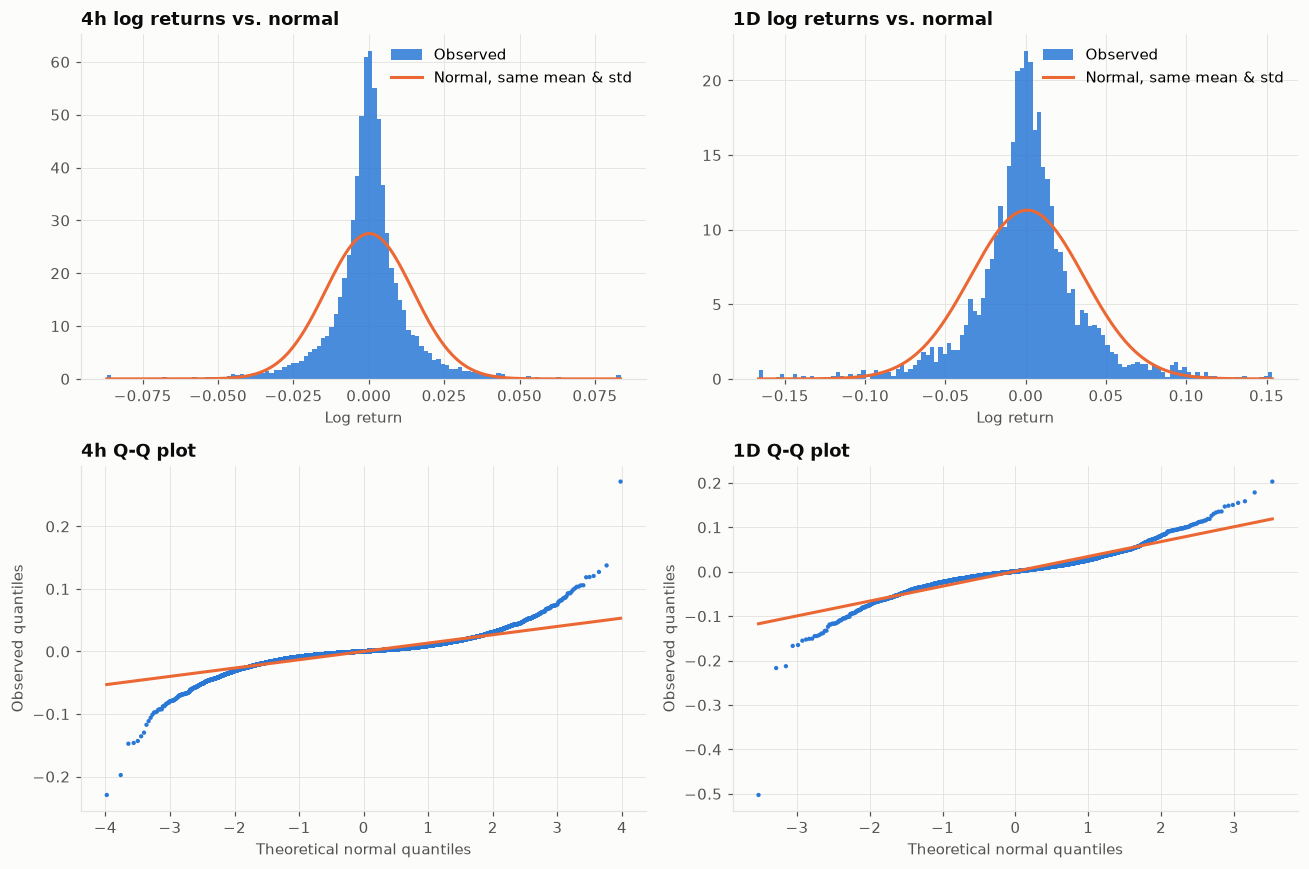

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, rule in enumerate(["4h", "1D"]):
    r = returns[rule]
    ax = axes[0, col]
    clip = r.quantile([0.001, 0.999])
    ax.hist(r.clip(*clip), bins=120, density=True, color=BLUE, alpha=0.85, label="Observed")
    x = np.linspace(*clip, 400)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), color=ORANGE, linewidth=2,
            label="Normal, same mean & std")
    ax.set(title=f"{rule} log returns vs. normal", xlabel="Log return")
    ax.legend()

    ax = axes[1, col]
    (osm, osr), (slope, intercept, _) = stats.probplot(r, dist="norm")
    ax.scatter(osm, osr, s=8, color=BLUE, edgecolor="none")
    ax.plot(osm, slope * osm + intercept, color=ORANGE, linewidth=2)
    ax.set(title=f"{rule} Q-Q plot", xlabel="Theoretical normal quantiles", ylabel="Observed quantiles")
fig.tight_layout()
save(fig, "03_return_distribution")
plt.show()

In [21]:
def normality_tests(r: pd.Series) -> dict:
    sigma_3 = (np.abs(r - r.mean()) > 3 * r.std()).mean()
    return {
        "Jarque-Bera p": stats.jarque_bera(r).pvalue,
        "D'Agostino K² p": stats.normaltest(r).pvalue,
        "% beyond 3σ (normal: 0.27%)": 100 * sigma_3,
    }

pd.DataFrame({rule: normality_tests(r) for rule, r in returns.items()}).style.format("{:.3g}")

,1h,4h,1D
Jarque-Bera p,0,0,0
D'Agostino K² p,0,0,9.36e-245
% beyond 3σ (normal: 0.27%),1.95,1.93,1.63


**Interpretation**

* **Visually:** the histogram has a much taller, narrower peak and fatter tails than the normal curve. In the Q-Q plot the points bend away from the line at both ends, which is the classic **fat-tail S-shape**.
* **Statistically:** both tests reject normality with p ≈ 0. Under H₀ (normal returns), the probability of seeing data like ours is essentially zero.
* **Why not Shapiro–Wilk?** Chapter 4 recommends it for small and moderate samples. SciPy warns that its p-value is unreliable above **5,000 observations**, and we have 3,300 to 80,000. Jarque-Bera and D'Agostino are built from skewness and kurtosis, so they suit large samples.
* **Tail frequency:** 1.6–1.95% of candles move more than 3σ, about **6–7× more often** than the 0.27% a normal distribution implies.

**Consequences for modeling**

1. Use **robust statistics** (median, IQR, Spearman) alongside mean, std and Pearson.
2. Prefer models that do not assume normal inputs (tree ensembles), or scale features robustly.
3. A few extreme candles (COVID, March 2020) can dominate squared-error losses. This is one more reason for a classification target.

## Item 6 · Stationarity (ADF + KPSS)

The two tests have **opposite null hypotheses**, so using both gives a stronger conclusion:

| Test | H₀ | "Stationary" if |
|---|---|---|
| ADF (Augmented Dickey-Fuller) | series has a unit root (non-stationary) | p < 0.05 (reject H₀) |
| KPSS | series is stationary | p > 0.05 (fail to reject H₀) |

In [22]:
def stationarity(series: pd.Series) -> dict:
    s = series.dropna()
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    return {"ADF p": adf_p, "KPSS p": kpss_p,
            "verdict": "stationary" if adf_p < 0.05 and kpss_p > 0.05 else "non-stationary"}

daily = frames["1D"]
pd.DataFrame({
    "log price (1D)": stationarity(np.log(daily["close"])),
    "log return (1D)": stationarity(returns["1D"]),
    "log return (4h)": stationarity(returns["4h"]),
}).T

C:\Users\Mega Pc\AppData\Local\Temp\ipykernel_34500\2531564842.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(s, autolag="AIC")[1]
C:\Users\Mega Pc\AppData\Local\Temp\ipykernel_34500\2531564842.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_p = kpss(s, regression="c", nlags="auto")[1]
C:\Users\Mega Pc\

,ADF p,KPSS p,verdict
log price (1D),0.558964,0.01,non-stationary
log return (1D),0.0,0.1,stationary
log return (4h),0.0,0.1,stationary


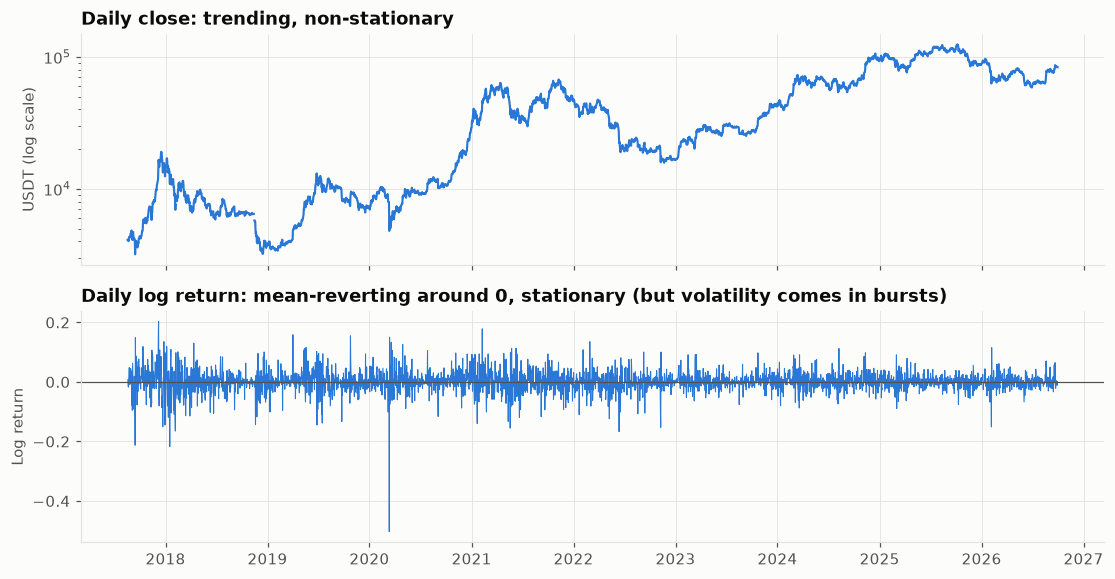

In [23]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(daily.index, daily["close"], color=BLUE)
ax1.set_yscale("log")
ax1.set(title="Daily close: trending, non-stationary", ylabel="USDT (log scale)")
ax2.plot(returns["1D"].index, returns["1D"], color=BLUE, linewidth=0.7)
ax2.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax2.set(title="Daily log return: mean-reverting around 0, stationary (but volatility comes in bursts)",
        ylabel="Log return")
save(fig, "03_price_vs_returns")
plt.show()

**Interpretation**

* **Log price:** ADF fails to reject a unit root (p ≈ 0.56) and KPSS rejects stationarity (p ≤ 0.01). Both tests agree it is **non-stationary**. Its mean and variance drift over time, so a model trained on 2019 prices has seen a different "world" than 2026.
* **Log returns:** ADF rejects the unit root (p ≈ 0) and KPSS does not reject stationarity. Both agree it is **stationary**.
* **Decision:** features and the target are built from **returns and ratios**, never raw price levels. This also explains why correlating raw prices is misleading: two trending series correlate strongly even when they are unrelated (spurious correlation).
* The lower plot already hints at item 7: calm periods and turbulent periods cluster together.

## Item 7 · Autocorrelation: is the past informative?

* **ACF of returns** asks whether direction persists or reverses.
* **ACF of squared returns** asks whether *volatility* persists (volatility clustering).
* **Ljung-Box test:** H₀ says there is no autocorrelation up to lag k.

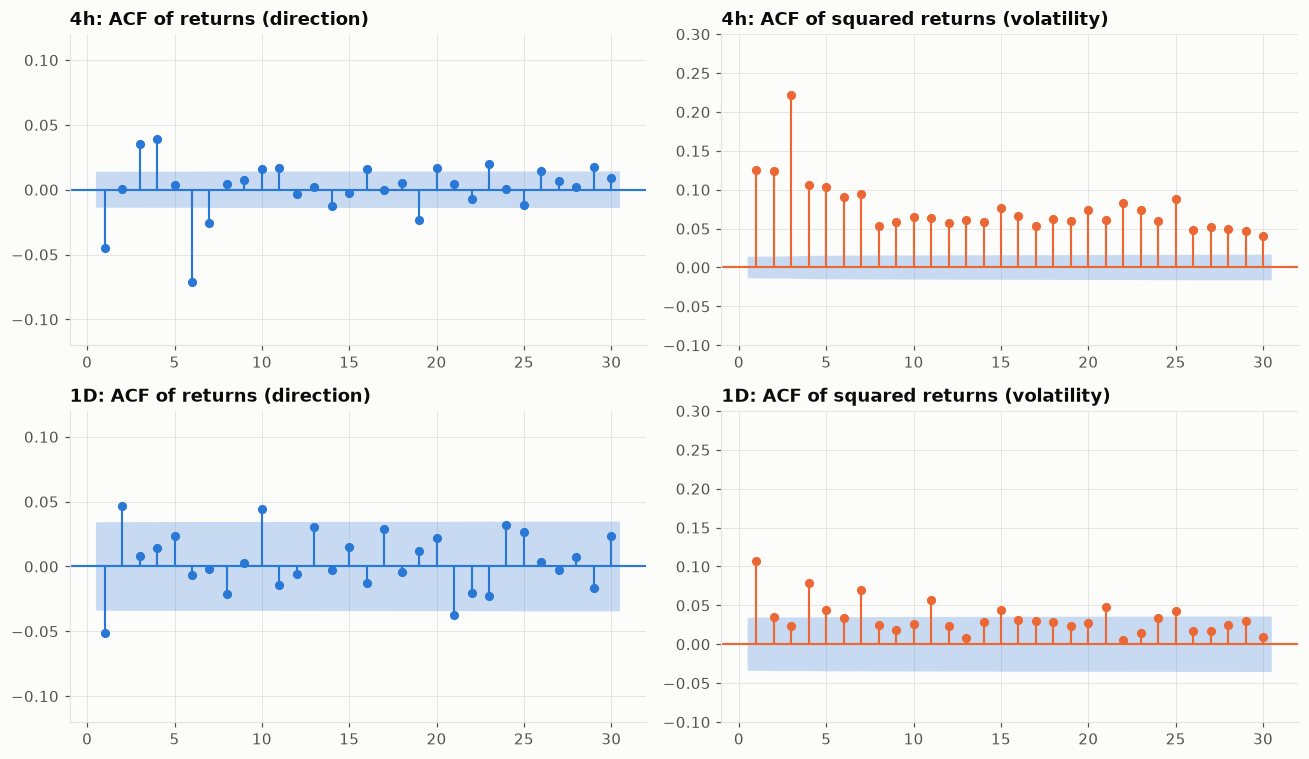

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
lags = 30
for row, rule in enumerate(["4h", "1D"]):
    r = returns[rule]
    plot_acf(r, lags=lags, ax=axes[row, 0], zero=False, color=BLUE, vlines_kwargs={"colors": BLUE})
    axes[row, 0].set(title=f"{rule}: ACF of returns (direction)", ylim=(-0.12, 0.12))
    plot_acf(r**2, lags=lags, ax=axes[row, 1], zero=False, color=ORANGE, vlines_kwargs={"colors": ORANGE})
    axes[row, 1].set(title=f"{rule}: ACF of squared returns (volatility)", ylim=(-0.1, 0.3))
fig.tight_layout()
save(fig, "03_acf")
plt.show()

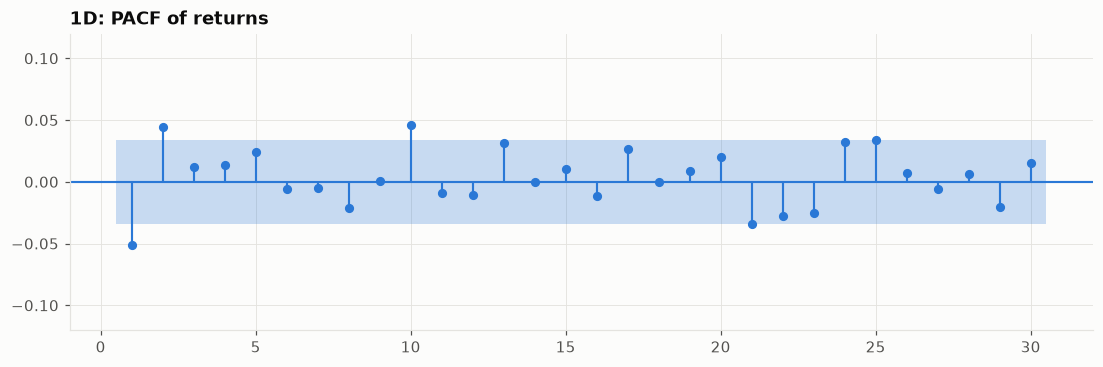

In [25]:
fig, ax = plt.subplots(figsize=(12, 3.5))
plot_pacf(returns["1D"], lags=lags, ax=ax, zero=False, method="ywm", color=BLUE,
          vlines_kwargs={"colors": BLUE})
ax.set(title="1D: PACF of returns", ylim=(-0.12, 0.12))
plt.show()

In [26]:
rows = {}
for rule, r in returns.items():
    rows[rule] = {
        "lag-1 autocorr (returns)": r.autocorr(1),
        "Ljung-Box p, returns (10 lags)": acorr_ljungbox(r, lags=[10]).lb_pvalue.iloc[0],
        "lag-1 autocorr (squared)": (r**2).autocorr(1),
        "Ljung-Box p, squared (10 lags)": acorr_ljungbox(r**2, lags=[10]).lb_pvalue.iloc[0],
    }
pd.DataFrame(rows).style.format("{:.3g}")

,1h,4h,1D
lag-1 autocorr (returns),-0.0422,-0.0452,-0.0514
"Ljung-Box p, returns (10 lags)",3.5e-48,2.19e-41,0.00282
lag-1 autocorr (squared),0.183,0.125,0.107
"Ljung-Box p, squared (10 lags)",0,0,3.19e-16


**Interpretation: the most important finding of this EDA**

* **Direction is barely predictable.** The lag-1 autocorrelation of returns is small and *negative*, about −0.04 to −0.05: a slight tendency for a move to partially reverse. Ljung-Box calls it statistically significant (p < 0.05), because with tens of thousands of observations even tiny effects become significant. But an autocorrelation of −0.05 explains only about **0.25%** of the variance (r² = 0.0025). **Statistical significance ≠ practical significance.**
* **Look beyond lag 1 on the 4h plot.** The most negative bar is at **lag 6 = 24 hours** (≈ −0.07). Moves tend to partially reverse one day later, so a feature like the "return over the last 24h" is a candidate. The squared-return ACF also spikes at **lag 3 = 12h**, which hints at an intraday pattern (e.g. Asian vs. US sessions). Hour-of-day seasonality (EDA item 8, currently out of scope) would test this.
* **Volatility is clearly predictable.** The ACF of squared returns is strongly positive at many lags, and Ljung-Box gives p ≈ 0. Large moves follow large moves. This is the *volatility clustering* that GARCH models describe.

**Consequences**

1. Expect modest direction accuracy, a few points above the baseline at best. That is normal for this problem, and our success criteria are defined relative to baselines for exactly this reason.
2. **Volatility features** (rolling std, high–low range, ATR) are the most promising inputs. They tell the model *when* a large move is likely, even if not its sign.
3. A slight short-term reversal effect exists. Lagged returns are worth including as features.

## Item 10 · Correlation with the future return

We correlate candidate variables at time *t* with the **forward** return from close *t* to close *t + 1 candle*: first with its sign (direction), then with its absolute size (how big the next move is).
All variables are scale-free (returns, ratios, logs), so the spurious-correlation trap from item 6 is avoided.

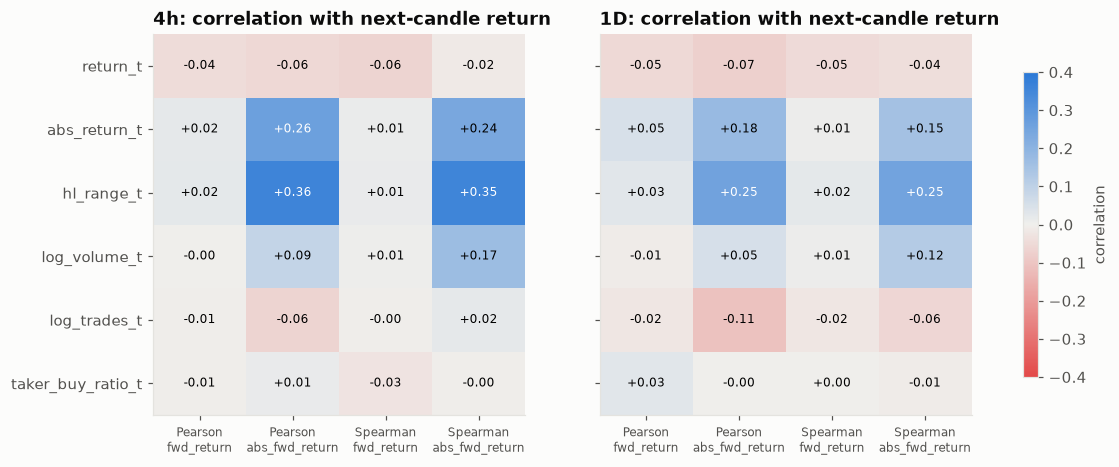

In [27]:
def candidate_variables(df: pd.DataFrame) -> pd.DataFrame:
    ret = log_returns(df["close"])
    fwd = forward_log_return(df["close"])
    return pd.DataFrame({
        "return_t": ret,
        "abs_return_t": ret.abs(),
        "hl_range_t": np.log(df["high"] / df["low"]),
        "log_volume_t": np.log(df["volume"].where(df["volume"] > 0)),
        "log_trades_t": np.log(df["number_of_trades"].where(df["number_of_trades"] > 0)),
        "taker_buy_ratio_t": taker_buy_ratio(df),
        "fwd_return": fwd,
        "abs_fwd_return": fwd.abs(),
    }).dropna()

targets = ["fwd_return", "abs_fwd_return"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, rule in zip(axes, ["4h", "1D"]):
    data = candidate_variables(frames[rule])
    corr = pd.concat({
        "Pearson": data.corr("pearson")[targets],
        "Spearman": data.corr("spearman")[targets],
    }, axis=1).drop(index=targets)
    im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-0.4, vmax=0.4, aspect="auto")
    ax.set_xticks(range(4), [f"{m}\n{t}" for m, t in corr.columns], fontsize=8)
    ax.set_yticks(range(len(corr)), corr.index if ax is axes[0] else [])
    ax.grid(False)
    for (i, j), v in np.ndenumerate(corr.values):
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.25 else "black")
    ax.set_title(f"{rule}: correlation with next-candle return")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation")
save(fig, "03_correlation")
plt.show()

**Interpretation**

* **Direction (`fwd_return`):** every correlation is within about ±0.06. No single raw variable predicts the sign of the next move linearly. The only consistent one is `return_t`, at about −0.05, which is the reversal effect from item 7. Volume and buy pressure show nothing *on their own*. They may still help in combination or through nonlinear effects, which a tree model can capture and a correlation cannot.
* **Magnitude (`abs_fwd_return`):** the high–low range (≈ +0.35 Spearman at 4h), the absolute return (≈ +0.24) and volume (≈ +0.17) clearly predict **how big** the next move will be. This confirms the volatility-clustering result from a different angle.
* **Pearson vs. Spearman:** they mostly agree. The clearest difference is volume vs. next-move size at 4h (Pearson ≈ 0.09, Spearman ≈ 0.17): a few extreme candles weaken the linear fit, while the rank-based Spearman, which is robust to the fat tails from item 4, sees the monotonic relationship.

**Implication for the agent:** even when the direction model has low confidence, a volatility estimate is useful for **position sizing** (trade smaller when the expected move is large and uncertain).

## Item 11 · Target analysis: choosing the horizon and the flat threshold

The label is **UP** if the forward log return > +θ, **DOWN** if < −θ, and **FLAT** otherwise.
θ controls the class balance. It should also exceed the **round-trip trading cost** (2 × 0.1% fee = 0.2%), so that "UP" means a move worth trading.

In [28]:
rows = []
for rule in config.CANDIDATE_HORIZONS:
    fwd = forward_log_return(frames[rule]["close"])
    for theta in config.CANDIDATE_FLAT_THRESHOLDS + (0.02,):
        shares = direction_label(fwd, theta).value_counts(normalize=True)
        rows.append({"horizon": rule, "θ %": 100 * theta,
                     "down %": 100 * shares.get(DOWN, 0), "flat %": 100 * shares.get(FLAT, 0),
                     "up %": 100 * shares.get(UP, 0)})
balance = pd.DataFrame(rows)
balance.style.format({"θ %": "{:.2f}", "down %": "{:.1f}", "flat %": "{:.1f}", "up %": "{:.1f}"}).hide(axis="index")

horizon,θ %,down %,flat %,up %
4h,0.10,42.3,12.6,45.2
4h,0.25,34.2,29.1,36.8
4h,0.50,24.3,50.0,25.8
4h,1.00,13.5,72.2,14.3
4h,2.00,5.5,89.1,5.5
1D,0.10,46.4,4.6,49.0
1D,0.25,43.2,10.9,45.8
1D,0.50,38.1,21.1,40.8
1D,1.00,29.7,37.8,32.6
1D,2.00,18.6,60.9,20.5


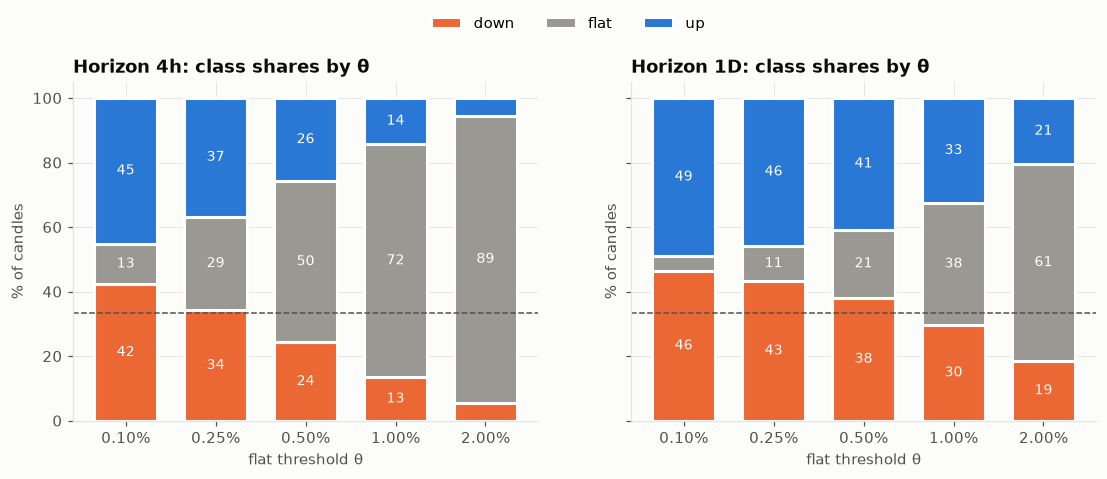

4h: median |move| = 0.50%  → a 0.2% round-trip fee costs 40% of a typical move
1D: median |move| = 1.47%  → a 0.2% round-trip fee costs 14% of a typical move


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, rule in zip(axes, config.CANDIDATE_HORIZONS):
    sub = balance[balance["horizon"] == rule].reset_index(drop=True)
    labels = [f"{t:.2f}%" for t in sub["θ %"]]
    bottom = np.zeros(len(sub))
    for cls in ["down", "flat", "up"]:
        values = sub[f"{cls} %"].to_numpy()
        ax.bar(labels, values, bottom=bottom, color=CLASS_COLORS[cls], label=cls,
               edgecolor="white", linewidth=2, width=0.7)
        for x, (b, v) in enumerate(zip(bottom, values)):
            if v >= 8:
                ax.text(x, b + v / 2, f"{v:.0f}", ha="center", va="center", color="white", fontsize=9)
        bottom += values
    ax.axhline(100 / 3, color=TEXT_SECONDARY, linestyle="--", linewidth=1)
    ax.set(title=f"Horizon {rule}: class shares by θ", xlabel="flat threshold θ", ylabel="% of candles")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncols=3, bbox_to_anchor=(0.5, 1.06))
save(fig, "03_class_balance")
plt.show()

for rule in config.CANDIDATE_HORIZONS:
    fwd = forward_log_return(frames[rule]["close"]).abs()
    print(f"{rule}: median |move| = {100 * fwd.median():.2f}%  "
          f"→ a 0.2% round-trip fee costs {0.2 / (100 * fwd.median()):.0%} of a typical move")

**Interpretation and recommendation**

| | 4h horizon | 1D horizon |
|---|---|---|
| Samples | ~20,000 | ~3,300 |
| Median absolute move | ~0.50% | ~1.47% |
| Fee as a share of a typical move | **~40%** | **~14%** |
| θ giving roughly balanced classes (down / flat / up %) | ≈ 0.25% (34 / 29 / 37) | ≈ 1.0% (30 / 38 / 33) |

* **The 4h horizon** gives 6× more training samples. But the fee eats about 40% of a typical move, and a θ of 0.25% barely clears the 0.2% round-trip cost. Trading on many of these signals would lose money to fees even with correct predictions.
* **The 1D horizon** has far fewer samples, but the typical move is about 7× the fee. Its balanced θ of 1% is a meaningful move, and it matches the update rhythm of daily news sentiment, which the agent will use.

**Recommended label: 1D horizon, θ = 1%.** This gives three roughly balanced classes and keeps the "flat = not worth trading" meaning.
A fallback to discuss with the team is 4h / θ = 0.5% (50% flat), if more samples are needed.
This is a **team decision**. The table above is the evidence to discuss.

> ⚠️ **Leakage warning for the modeling phase:** the label at *t* uses `close[t + 1 candle]`. Every feature for row *t* must use data up to `close[t]` only, and the train/validation/test split must be **chronological**, never random.

## Item 12 · Baselines (the bar to clear)

In [30]:
rows = {}
for rule, theta in [("1D", 0.01), ("4h", 0.005)]:
    labels = direction_label(forward_log_return(frames[rule]["close"]), theta)
    maj = majority_baseline(labels)
    per = persistence_baseline(labels)
    rows[f"{rule}, θ={100 * theta:.1f}%"] = {
        "majority class": {DOWN: "down", FLAT: "flat", UP: "up"}[maj["class"]],
        "majority accuracy": maj["accuracy"], "majority macro-F1": maj["macro_f1"],
        "persistence accuracy": per["accuracy"], "persistence macro-F1": per["macro_f1"],
    }
pd.DataFrame(rows).T.style.format({c: "{:.3f}" for c in
    ["majority accuracy", "majority macro-F1", "persistence accuracy", "persistence macro-F1"]})

,majority class,majority accuracy,majority macro-F1,persistence accuracy,persistence macro-F1
"1D, θ=1.0%",flat,0.378,0.183,0.361,0.356
"4h, θ=0.5%",flat,0.500,0.222,0.427,0.374


In [31]:
bh = pd.DataFrame({rule: buy_and_hold(frames[rule]["close"], rule) for rule in ["4h", "1D"]}).T
bh.style.format({"total_return": "{:+.0%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"})

,total_return,sharpe,max_drawdown
4h,+1819%,0.81,-85%
1D,+1931%,0.82,-83%


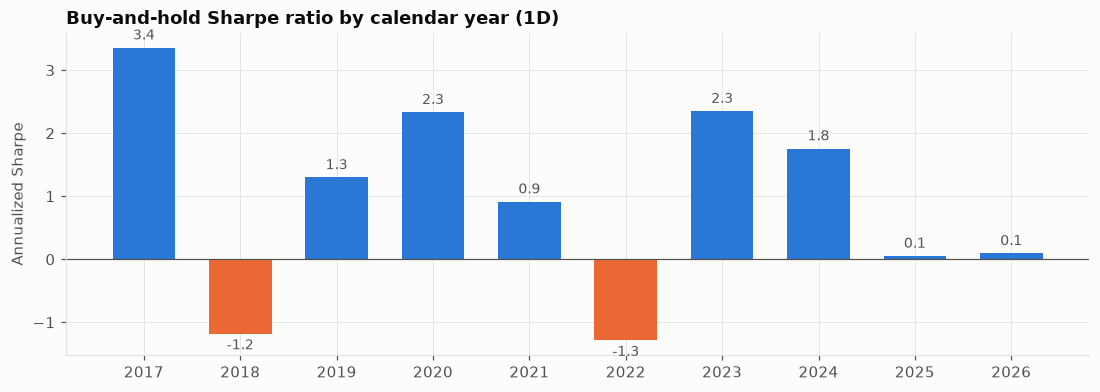

,return,sharpe
year,,
2017,+211%,3.36
2018,-73%,-1.18
2019,+91%,1.30
2020,+319%,2.33
2021,+51%,0.91
2022,-64%,-1.29
2023,+156%,2.35
2024,+121%,1.76
2025,-6%,0.05


In [32]:
yearly = []
daily_ret = returns["1D"]
for year, r in daily_ret.groupby(daily_ret.index.year):
    simple = np.expm1(r)
    yearly.append({"year": year, "return": np.expm1(r.sum()),
                   "sharpe": simple.mean() / simple.std() * np.sqrt(365)})
yearly = pd.DataFrame(yearly).set_index("year")

fig, ax = plt.subplots(figsize=(12, 3.8))
colors = [BLUE if v >= 0 else ORANGE for v in yearly["sharpe"]]
ax.bar(yearly.index.astype(str), yearly["sharpe"], color=colors, width=0.65)
ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
for x, v in enumerate(yearly["sharpe"]):
    ax.text(x, v + (0.08 if v >= 0 else -0.08), f"{v:.1f}", ha="center",
            va="bottom" if v >= 0 else "top", fontsize=9, color=TEXT_SECONDARY)
ax.set(title="Buy-and-hold Sharpe ratio by calendar year (1D)", ylabel="Annualized Sharpe")
save(fig, "03_bh_sharpe_by_year")
plt.show()
yearly.style.format({"return": "{:+.0%}", "sharpe": "{:.2f}"})

**Interpretation**

* **Model baselines (data-mining success criterion):** at 1D / θ = 1%, always predicting the majority class gets about 38% accuracy but a macro-F1 of only about 0.18, because it ignores two of the three classes. Persistence ("same as the last realized move") is the stronger baseline to beat on macro-F1. A model must beat **both**, on a chronological test set.
* **Agent baseline (business success criterion):** buy-and-hold BTC has a full-period Sharpe of about **0.8**, with a maximum drawdown around **−83%**.
* **The baseline depends heavily on the test window.** Buy-and-hold Sharpe swings from strongly negative (2018, 2022) to above 2 in bull years. When the test period is chosen during Data Preparation, the business criterion must be measured on **exactly that window**. A strategy that is mostly in cash can beat buy-and-hold in a bear-market test year without being "smart".

## Summary of findings → inputs for Data Preparation & Modeling

| # | Finding | Decision / implication |
|---|---|---|
| 3 | Drift ≪ noise; annualized vol ≈ 70% | Direction prediction is inherently hard; judge the model against baselines |
| 4 | Fat tails, negative skew, normality rejected | Robust scaling, tree models, classification target |
| 6 | Price non-stationary, returns stationary | Build all features from returns and ratios |
| 7 | Tiny reversal effect; strong volatility clustering | Lagged returns plus volatility features (rolling std, range, ATR) |
| 10 | No linear predictor of direction; range and volume predict magnitude | Use nonlinear models; give the agent a volatility signal for sizing |
| 11 | 1D gives a typical move ≈ 7× the fees | **Recommended target: 1D, θ = 1%** (team to confirm) |
| 12 | Majority, persistence and buy-and-hold computed | These are the bars from the success criteria |